In [ ]:
# SETUP - run this cell once, then any cell below on its own #################
#
# Every other cell needs this one and nothing else. Packages, paths and the
# build steps all live here, so after reopening the notebook you run this and
# then whichever cell you actually want.
#
# The build steps are functions rather than inline code because each one is
# needed by more than one cell downstream. They re-read from disk each call
# (a few seconds), which is what buys the independence.
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from tqdm import tqdm

PLOT_OUTPUT = (
    "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/plots/"
)

# ---- FHS indicators -------------------------------------------------------
FHS_ROOT = "/mnt/share/forecasting/data/32/future/death/future_death_aggregated_rate_s130v156_q0_indicators/"
U5M_PATH = os.path.join(FHS_ROOT, "u5mr_5q0.csv")
NMR_PATH = os.path.join(FHS_ROOT, "nmr_28dayq0.csv")
# FHS publishes deaths per 1000 livebirths; the pipeline works in probability
FHS_RATE_PER = 1000.0

# ---- RRA neonatal results -------------------------------------------------
NMR_RRA_ROOT = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_10_08.01/"
# The ORIGINAL model draws - inference output, before the residual step. The
# scenario differences are taken from these. The residual step adds its
# residual and GBD anchor identically to every scenario, so they cancel out of
# any difference between scenarios; but it then clips every draw at zero,
# which flattens the gap wherever the residual has dragged values negative.
# On these runs that clip removes 15% of the neonatal and 59% of the under-5
# climate effect by 2100 (cumulative, ssp585 - ssp126). The original draws
# are never clipped.
NMR_RRA_REF_PATH = os.path.join(NMR_RRA_ROOT, "ssp245.parquet")
NMR_RRA_BETTER_PATH = os.path.join(NMR_RRA_ROOT, "ssp126.parquet")
NMR_RRA_WORSE_PATH = os.path.join(NMR_RRA_ROOT, "ssp585.parquet")

# The shifted draws (model + residual + GBD anchor, clipped at zero). Not used
# by the method; kept for comparing against.
NMR_RRA_REF_SHIFTED_PATH = os.path.join(NMR_RRA_ROOT, "ssp245_shifted.parquet")
NMR_RRA_BETTER_SHIFTED_PATH = os.path.join(NMR_RRA_ROOT, "ssp126_shifted.parquet")
NMR_RRA_WORSE_SHIFTED_PATH = os.path.join(NMR_RRA_ROOT, "ssp585_shifted.parquet")

# ---- shared inputs for aggregation ---------------------------------------
PLOT_OUTPUT = (
    "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/plots/"
)
NEONATAL_PLOT_FILE = "neonatal_superregion_scenarios.png"
NEONATAL_YLABEL = "Neonatal deaths per 1000 livebirths"
U5M_YLABEL = "Under-5 deaths per 1000 livebirths"
NEONATAL_TABLE_FILE = "neonatal_cumulative_scenario_differences.csv"

# Live births: the weight for both mortality indicators. 28q0 and 5q0 are
# probabilities per live birth, so births are what they are aggregated by and
# what turns a rate into a count of deaths. Release 32, scenario 130, matching
# the FHS mortality series above. National only and no sex dimension; see
# load_live_births_weights for how it is split below that.
LIVE_BIRTHS_PATH = "/mnt/share/forecasting/data/32/future/live_births/future_livebirth_s130v97/live_births.nc"
# maternal age groups 15-19 .. 45-49; the file also carries 24, their sum,
# which must be left out or every birth is counted twice
LIVE_BIRTHS_MATERNAL_AGES = [8, 9, 10, 11, 12, 13, 14]

# Population, ages 2 + 3. Used ONLY to split national births across
# subnational locations and sexes, never as a weight in its own right.
# Release 32, scenario 130, the file the pipeline pins in
# rra_climate_health/inference/run_inference.py:44 in the _2 clone.
FHS_POP_PATH = "/mnt/share/forecasting/data/32/future/population/future_population_s130v41/population.nc"
FHS_HIERARCHY_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/input/fhs_hierarchy.parquet"
# early + late neonatal, which is what constants.AGE_GROUP_AGGREGATES says
# age group 42 is made of
NEONATAL_POP_PARTS = [2, 3]

# ---- keys, labels and analysis settings ----------------------------------
SCEN_KEYS = ["age_group_id", "sex_id", "location_id", "year_id"]
NEONATAL_AGE_GROUP_ID = 42
BOTH_SEXES_ID = 3  # FHS publishes a Both row; RRA models sexes 1 and 2
SCENARIO_LABELS = {"reference": "ssp245", "better": "ssp126", "worse": "ssp585"}
REFERENCE_SSP, BETTER_SSP, WORSE_SSP = "ssp245", "ssp126", "ssp585"
SCENARIO_ORDER = ["ssp126", "ssp245", "ssp585"]
SCENARIO_COLOURS = ["#2a78d6", "#52514e", "#eb6834"]
# shown on the figure; the SSP names stay in the data
SCENARIO_DISPLAY = {"ssp126": "RCP 2.6", "ssp245": "RCP 4.5", "ssp585": "RCP 8.5"}
SCENARIO_LEGEND_TITLE = "Representative Control Pathways (RCP) Scenarios"
SCENARIO_PAIRS = [("ssp585", "ssp126"), ("ssp585", "ssp245"), ("ssp245", "ssp126")]
FIRST_FORECAST_YEAR = 2024
ANALYSIS_YEARS = [2050, 2100]
# one draw column: there is no uncertainty to carry, so the point estimate is
# written straight in. Consumers average across draws, which returns it
# unchanged, and the name stays a subset of the population file's draw_0..249.
DRAW_COLS = ["draw_0"]

# filled in by apply_deltas_to_fhs(): how many final values the floor at
# zero touched, by scenario. The only clip in this notebook.
nmr_fhs_clipped: dict[str, int] = {}


def _draw_mean(path, name):
    """Mean over the draw columns of an RRA results file, keyed for a merge."""
    d = pd.read_parquet(path).mean(axis=1).rename(name).reset_index()
    return d.drop(columns=[c for c in ("scenario",) if c in d.columns])


def load_neonatal_population():
    """Ages 2 + 3 population, by location, year and sex.

    Used only to split live births below the level the births file reports;
    it is not itself a weight anywhere in this notebook.
    """
    return (
        xr.open_dataset(FHS_POP_PATH)["draws"]
        .sel(age_group_id=NEONATAL_POP_PARTS)
        .sum("age_group_id")
        .mean("draw")
        .squeeze(drop=True)
        .to_dataframe(name="population")
        .reset_index()[["location_id", "year_id", "sex_id", "population"]]
    )


def load_live_births_weights():
    """Live births at every RRA most-detailed location, by year and sex.

    28q0 and 5q0 are probabilities per live birth, so live births are the
    weight that matches them - for aggregating a rate across locations and
    for turning a rate into a death count. The births file is national only
    and has no sex dimension, so each country's births are divided among its
    most-detailed (location, sex) cells in proportion to their ages 2 + 3
    population:

        births[l, s] = births[country] * pop23[l, s] / pop23[country]

    National totals are therefore preserved exactly. The split matters for
    the 280 subnational locations in 11 countries (India, China, Nigeria,
    Brazil, USA, ...) and for the sex split everywhere. Ages 2 + 3 is used for
    both measures because it is the closest births proxy there is: the 0-27
    day population runs 0.075-0.077 births per birth across 95% of countries,
    where the under-5 population ranges 4.6-5.6 and would tilt the split
    toward countries whose fertility has fallen fastest.
    """
    hier = pd.read_parquet(FHS_HIERARCHY_PATH)
    md = hier.loc[
        hier["most_detailed"] == 1, ["location_id", "path_to_top_parent"]
    ].copy()
    # the level-3 ancestor in each location's own path is its country
    md["country_id"] = md["path_to_top_parent"].str.split(",").str[3].astype(int)
    md = md[["location_id", "country_id"]]

    births = (
        xr.open_dataset(LIVE_BIRTHS_PATH)["livebirths"]
        .sel(age_group_id=LIVE_BIRTHS_MATERNAL_AGES)
        .sum("age_group_id")
        .mean("draw")
        .squeeze(drop=True)
        .to_dataframe(name="country_births")
        .reset_index()[["location_id", "year_id", "country_births"]]
        .rename(columns={"location_id": "country_id"})
    )

    pop = load_neonatal_population().merge(md, on="location_id", how="inner")
    pop["country_pop"] = pop.groupby(["country_id", "year_id"])["population"].transform(
        "sum"
    )
    w = pop.merge(births, on=["country_id", "year_id"], how="inner")
    w["births"] = w["country_births"] * w["population"] / w["country_pop"]
    return w[["location_id", "year_id", "sex_id", "births"]]


def rra_scenario_levels():
    """The three neonatal scenario levels at RRA's own locations.

    Taken from the ORIGINAL model draws, before the residual step; see the
    path constants for why.
    """
    return (
        _draw_mean(NMR_RRA_REF_PATH, "ref")
        .merge(_draw_mean(NMR_RRA_BETTER_PATH, "better"), on=SCEN_KEYS)
        .merge(_draw_mean(NMR_RRA_WORSE_PATH, "worse"), on=SCEN_KEYS)
    )


def aggregate_scenarios(scenarios, weights, age_group_id):
    """RRA's scenario levels and differences at every location in the hierarchy.

    Explode `path_to_top_parent` so each most-detailed location lands in every
    ancestor, then take the births-weighted mean of each scenario - the
    arithmetic of the pipeline's aggregate_forecast_hierarchy(counts=False),
    with live births in place of its population weight. sex_id 3 is added as
    the both-sex aggregate so FHS's "Both" rows can be matched. Summed births
    travel with it, for the counts step.

    The differences are absolute, and since a weighted mean is linear it makes
    no difference whether they are taken before or after aggregating:
    mean(better) - mean(ref) is mean(better - ref). Nothing is clipped here.

    This is the ONLY thing aggregated anywhere in this notebook. FHS already
    publishes every level correctly; re-deriving its aggregates would only
    replace them with worse ones.
    """
    hier = pd.read_parquet(FHS_HIERARCHY_PATH)
    d = scenarios.merge(weights, on=DRAW_IDX, how="inner")
    anc = hier.loc[
        hier["most_detailed"] == 1, ["location_id", "path_to_top_parent"]
    ].copy()
    anc["agg_id"] = anc["path_to_top_parent"].str.split(",")
    anc = anc.explode("agg_id")
    anc["agg_id"] = anc["agg_id"].astype(int)
    d = d.merge(anc[["location_id", "agg_id"]], on="location_id")

    levels = ["ref", "better", "worse"]
    for col in levels:
        d[f"_w_{col}"] = d[col] * d["births"]

    def _collapse(frame, keys):
        out = frame.groupby(keys, as_index=False)[
            [f"_w_{c}" for c in levels] + ["births"]
        ].sum()
        for col in levels:
            out[col] = out[f"_w_{col}"] / out["births"]
        return out.drop(columns=[f"_w_{c}" for c in levels])

    by_sex = _collapse(d, ["agg_id", "year_id", "sex_id"])
    both = _collapse(d, ["agg_id", "year_id"])
    both["sex_id"] = BOTH_SEXES_ID
    out = pd.concat([by_sex, both], ignore_index=True)
    out["abs_better"] = out["better"] - out["ref"]
    out["abs_worse"] = out["worse"] - out["ref"]
    out["age_group_id"] = age_group_id
    return out.rename(columns={"agg_id": "location_id"})


def aggregate_rra_deltas():
    """Neonatal scenario differences, aggregated to every location."""
    return aggregate_scenarios(
        rra_scenario_levels(), load_live_births_weights(), NEONATAL_AGE_GROUP_ID
    )


def apply_deltas_to_fhs(fhs_path, deltas):
    """FHS series as published, plus the aggregated RRA difference.

        out = fhs_published + (scenario - reference) * 1000

    so the gap between scenarios is RRA's and the levels are FHS's. The floor
    at zero is the last thing applied and the only clip in this notebook - a
    rate cannot be negative. `nmr_fhs_clipped` records how many values it
    touched.
    """
    fhs = pd.read_csv(fhs_path)
    wide = fhs.merge(
        deltas[SCEN_KEYS + ["abs_better", "abs_worse", "births"]],
        on=SCEN_KEYS,
        how="inner",
    )
    for lab in ("better", "worse"):
        wide[f"mean_{lab}"] = wide["mean"] + wide[f"abs_{lab}"] * FHS_RATE_PER

    keep = list(fhs.columns.drop(["upper", "lower"])) + ["births"]
    base = wide[keep]
    parts = [base.assign(scenario="reference")]
    for lab in ("better", "worse"):
        p = base.copy()
        p["scenario"] = lab
        p["mean"] = wide[f"mean_{lab}"].to_numpy()
        parts.append(p)
    out = pd.concat(parts, ignore_index=True)

    nmr_fhs_clipped.clear()
    for lab in ("reference", "better", "worse"):
        nmr_fhs_clipped[lab] = int(((out["scenario"] == lab) & (out["mean"] < 0)).sum())
    out["mean"] = out["mean"].clip(lower=0.0)
    return out


def build_nmr_fhs_scenarios():
    """FHS neonatal series with the RRA scenario differences added."""
    return apply_deltas_to_fhs(NMR_PATH, aggregate_rra_deltas())


def counts_from_scenarios(scen):
    """Deaths and live births, at the globe and super regions, Both sexes.

    deaths = rate per 1000 / 1000 * live births. The rates come from FHS at
    each aggregate level, and the births are the most-detailed births summed
    to that same level, so nothing is summed up the hierarchy here.
    """
    hier = pd.read_parquet(FHS_HIERARCHY_PATH)
    table_locs = set(hier.loc[hier["level"] < 2, "location_id"])
    out = scen[
        scen["location_id"].isin(table_locs) & (scen["sex_id"] == BOTH_SEXES_ID)
    ].copy()
    out["count"] = out["mean"] / FHS_RATE_PER * out["births"]
    out["rate"] = out["mean"]
    out["scenario"] = out["scenario"].map(SCENARIO_LABELS)
    return out[
        ["location_id", "scenario", "year_id", "count", "births", "rate"]
    ].reset_index(drop=True)


def build_nmr_fhs_counts():
    """Neonatal deaths and live births, globe and super regions."""
    return counts_from_scenarios(build_nmr_fhs_scenarios())


def build_nmr_fhs_shifted_prevalence():
    """The scenario series in the pipeline's shifted_prevalence shape.

    Filtered to the most-detailed locations and sexes 1/2, because that is
    what the pipeline's own file holds. build_nmr_fhs_scenarios now also
    carries the aggregate levels and the Both-sex rows, which belong in the
    plots and the table but not in a file meant to be aggregated downstream -
    including them would double count.
    """
    hier = pd.read_parquet(FHS_HIERARCHY_PATH)
    detailed = set(hier.loc[hier["most_detailed"] == 1, "location_id"])
    f = build_nmr_fhs_scenarios()
    f = f[f["location_id"].isin(detailed) & (f["sex_id"] != BOTH_SEXES_ID)].copy()
    f["scenario"] = f["scenario"].map(SCENARIO_LABELS)
    if f["scenario"].isna().any():
        msg = "unmapped scenario label"
        raise ValueError(msg)
    return pd.DataFrame(
        np.repeat((f["mean"].to_numpy() / FHS_RATE_PER)[:, None], len(DRAW_COLS), 1),
        columns=DRAW_COLS,
        index=pd.MultiIndex.from_frame(
            f[["location_id", "year_id", "sex_id", "age_group_id", "scenario"]]
        ),
    ).sort_index()


# ---- child mortality (5q0) ------------------------------------------------
# RRA has no directly usable 5q0. The direct run (2026_10_01.01) is properly
# anchored but falls below 28q0 in 216 locations after 2023, which is
# impossible - neonatal deaths are a subset of under-5 deaths. 5q28 was
# modelled separately to fix that, so 5q0 is rebuilt from the two parts.
CM_RRA_ROOT = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/child_mortality/results/2026_10_16.01/"
# original model draws, as for neonatal; the forecast step has already
# combined the seven 5q28 strata into age group 1
NMR_RRA_DRAWS = {s: os.path.join(NMR_RRA_ROOT, f"{s}.parquet") for s in SCENARIO_ORDER}
CM_RRA_DRAWS = {s: os.path.join(CM_RRA_ROOT, f"{s}.parquet") for s in SCENARIO_ORDER}
UNDER5_AGE_GROUP_ID = 1
U5M_PLOT_FILE = "child_mortality_superregion_scenarios.png"
U5M_TABLE_FILE = "child_mortality_cumulative_scenario_differences.csv"

DRAW_IDX = ["location_id", "year_id", "sex_id"]


def rra_5q0_draws(scenario):
    """5q0 = 1 - (1 - 28q0) * (1 - 5q28), draw by draw, for one scenario.

    Draw by draw and not on the draw means, because the identity is not
    linear. Both parents are the original model draws, before the residual step.
    """

    def _load(path):
        d = pd.read_parquet(path).reset_index()
        return d.drop(columns=["age_group_id", "scenario"]).set_index(DRAW_IDX)

    neo = _load(NMR_RRA_DRAWS[scenario])
    cm = _load(CM_RRA_DRAWS[scenario]).reindex(neo.index)
    if cm.isna().any().any():
        msg = "28q0 and 5q28 do not cover the same location/year/sex rows"
        raise ValueError(msg)
    return 1.0 - (1.0 - neo) * (1.0 - cm)


def rra_5q0_scenario_levels():
    """The three recombined 5q0 scenario levels, at RRA's own locations."""
    draws = {s: rra_5q0_draws(s).mean(axis=1) for s in SCENARIO_ORDER}
    d = pd.DataFrame(
        {
            "ref": draws[REFERENCE_SSP],
            "better": draws[BETTER_SSP],
            "worse": draws[WORSE_SSP],
        }
    ).reset_index()
    d["age_group_id"] = UNDER5_AGE_GROUP_ID
    return d


def build_u5m_fhs_scenarios():
    """FHS under-5 series with the recombined RRA 5q0 scenario differences added."""
    deltas = aggregate_scenarios(
        rra_5q0_scenario_levels(), load_live_births_weights(), UNDER5_AGE_GROUP_ID
    )
    return apply_deltas_to_fhs(U5M_PATH, deltas)


def build_u5m_fhs_counts():
    """Under-5 deaths and live births, globe and super regions."""
    return counts_from_scenarios(build_u5m_fhs_scenarios())


def cumulative_difference_table(counts):
    """Cumulative deaths by scenario, the differences, and each as a percent.

    At ANALYSIS_YEARS, in whole deaths. For each location the three
    scenarios' own cumulative totals come first, then the three differences:

        cumulative[s]   = sum over 2024..year of deaths[s]
        deaths          = cumulative[A] - cumulative[B]
        pct_change_from_lower_scenario
                        = 100 * (cumulative[A] - cumulative[B]) / cumulative[B]

    B is always the lower-emission scenario of the pair (ssp126 under ssp245
    under ssp585), so the percent reads as "how many more deaths the higher-
    emission pathway brings, relative to the lower one". It is blank on the
    three level rows. Every value is rounded on its own, so a difference can
    sit one death away from the subtraction of its two rounded level rows.

    The reference row is FHS's own series; the other two are FHS plus the RRA
    scenario gap.
    """
    hier = pd.read_parquet(FHS_HIERARCHY_PATH)
    cum = counts.query("year_id >= @FIRST_FORECAST_YEAR").sort_values("year_id").copy()
    cum["cum_count"] = cum.groupby(["location_id", "scenario"])["count"].cumsum()
    wide = cum.pivot_table(
        index=["location_id", "year_id"], columns="scenario", values="cum_count"
    )
    rows = []
    for s in SCENARIO_ORDER:
        d = wide[s].rename("value").reset_index()
        d["pct"] = np.nan
        d["scenario"] = s
        rows.append(d)
    for a, b in SCENARIO_PAIRS:
        d = (wide[a] - wide[b]).rename("value").reset_index()
        d["pct"] = (100 * (wide[a] - wide[b]) / wide[b]).to_numpy()
        d["scenario"] = f"{a} - {b}"
        rows.append(d)
    row_order = {
        lab: k
        for k, lab in enumerate(
            SCENARIO_ORDER + [f"{a} - {b}" for a, b in SCENARIO_PAIRS]
        )
    }
    table = (
        pd.concat(rows)
        .query("year_id in @ANALYSIS_YEARS")
        .merge(
            hier[["location_id", "location_name", "sort_order"]],
            on="location_id",
            how="left",
        )
    )
    table["_row"] = table["scenario"].map(row_order)
    table = table.sort_values(["year_id", "sort_order", "_row"])
    table["deaths"] = table["value"].round().astype("int64")
    table["pct_change_from_lower_scenario"] = table["pct"].round(2)
    return table[
        [
            "year_id",
            "location_name",
            "scenario",
            "deaths",
            "pct_change_from_lower_scenario",
        ]
    ].reset_index(drop=True)


def plot_superregion_rates(counts, ylabel=NEONATAL_YLABEL, ncol=4):
    """Rate by scenario, one panel per globe/super region.

    Four panels across, so the globe and the seven super regions fill two
    rows exactly. One legend for the whole figure, below the panels, rather
    than a per-axes one competing with the curves. The y axis is shared, so
    panel heights are comparable at a glance - at the cost of flattening the
    low-mortality regions, which span 1.3-2.8 against Sub-Saharan Africa's
    7-23 per 1000.
    """
    hier = pd.read_parquet(FHS_HIERARCHY_PATH)
    locs = (
        hier[hier["location_id"].isin(counts.location_id.unique())]
        .query("level < 2")
        .sort_values("sort_order")
    )
    nrow = int(np.ceil(len(locs) / ncol))
    fig, axes = plt.subplots(
        nrow, ncol, figsize=(4.0 * ncol, 3.4 * nrow), sharex=True, sharey=True
    )
    handles = []
    for ax, (_, loc) in zip(axes.flatten(), locs.iterrows()):
        panel = counts[counts["location_id"] == loc["location_id"]]
        for scen, colour in zip(SCENARIO_ORDER, SCENARIO_COLOURS):
            s = panel[panel["scenario"] == scen].sort_values("year_id")
            (line,) = ax.plot(s["year_id"], s["rate"], color=colour, lw=2)
            if len(handles) < len(SCENARIO_ORDER):
                line.set_label(SCENARIO_DISPLAY[scen])
                handles.append(line)
        ax.set_title(loc["location_name"], fontsize=12)
        ax.grid(True, linestyle=":", alpha=0.6)
        ax.tick_params(labelsize=10)
    for ax in axes.flatten()[len(locs) :]:
        ax.set_visible(False)
    fig.supylabel(ylabel, fontsize=12)
    fig.tight_layout(rect=[0, 0.08, 1, 1])
    fig.legend(
        handles=handles,
        title=SCENARIO_LEGEND_TITLE,
        loc="lower center",
        ncol=len(SCENARIO_ORDER),
        frameon=False,
        fontsize=11,
        title_fontsize=12,
        bbox_to_anchor=(0.5, 0.0),
    )
    return fig

In [9]:
u5m_fhs_df = pd.read_csv(U5M_PATH)
nmr_fhs_df = pd.read_csv(NMR_PATH)
nmr_fhs_df.head()

,scenario,location_id,location_name,year_id,sex_id,sex_label,age_group_id,age_group_name,mean,upper,lower,measure_id,measure_name
0,reference,25318,Abia,2024,1,Male,42,Neonatal,28.532496,31.396305,26.037600,1,"death (rate per 1,000 livebirths)"
1,reference,25318,Abia,2024,2,Female,42,Neonatal,17.278570,19.181057,15.659551,1,"death (rate per 1,000 livebirths)"
2,reference,25318,Abia,2024,3,Both,42,Neonatal,23.065163,25.084101,21.236416,1,"death (rate per 1,000 livebirths)"
3,reference,25318,Abia,2025,1,Male,42,Neonatal,28.063256,31.166430,25.464744,1,"death (rate per 1,000 livebirths)"
4,reference,25318,Abia,2025,2,Female,42,Neonatal,17.126997,19.239748,15.488511,1,"death (rate per 1,000 livebirths)"


### NEONATAL

In [10]:
nmr_rra_worse_df = pd.read_parquet(NMR_RRA_WORSE_PATH).reset_index()
nmr_rra_better_df = pd.read_parquet(NMR_RRA_BETTER_PATH).reset_index()

In [11]:
# Apply RRA scenario differences to the FHS neonatal series ##################
#
# Same move as goal_keepers/.../ad_hoc/stunting_apply_genem_difs.py with the
# two roles swapped: there GENEM supplies the scenario spread and the Rapid
# Response series is modified, here RRA supplies the spread and FHS is
# modified.
#
#     out = fhs_published + (rra_scenario - rra_reference) * 1000
#
# ssp245 is the reference, ssp126 the better scenario and ssp585 the worse.
# The difference is ABSOLUTE, so the gap between scenarios is exactly RRA's
# gap and the levels are exactly FHS's. Only the central estimate is carried
# through; FHS upper/lower are dropped rather than shifted, since a shifted
# interval would look like a modelled one.
#
# Only the RRA difference is aggregated. FHS is used as published at every
# level - re-deriving its aggregates would only replace them with worse ones.
# The RRA rows exist at 473 most-detailed locations, and are rolled up to each
# ancestor by a LIVE-BIRTHS-weighted mean, because 28q0 is a probability per
# live birth.
#
# RRA comes from the ORIGINAL model draws, not the residual step's shifted
# ones. The residual and the GBD anchor are added identically to every
# scenario and cancel out of a scenario difference anyway; what the shifted
# files add is a clip at zero on every draw, which flattens the gap wherever
# the residual has pushed values negative. Nothing in this notebook clips
# until the very last step, where a final rate below zero is floored to zero;
# `nmr_fhs_clipped` reports how many values that touched.
nmr_fhs_scenarios_df = build_nmr_fhs_scenarios()
nmr_fhs_scenarios_df.head()

,scenario,location_id,location_name,year_id,sex_id,sex_label,age_group_id,age_group_name,mean,measure_id,measure_name,births
0,reference,25318,Abia,2024,1,Male,42,Neonatal,28.532496,1,"death (rate per 1,000 livebirths)",75506.964619
1,reference,25318,Abia,2024,2,Female,42,Neonatal,17.278570,1,"death (rate per 1,000 livebirths)",71993.337017
2,reference,25318,Abia,2024,3,Both,42,Neonatal,23.065163,1,"death (rate per 1,000 livebirths)",147500.301636
3,reference,25318,Abia,2025,1,Male,42,Neonatal,28.063256,1,"death (rate per 1,000 livebirths)",75437.097032
4,reference,25318,Abia,2025,2,Female,42,Neonatal,17.126997,1,"death (rate per 1,000 livebirths)",71910.712248


In [12]:
# Reshape to the pipeline's shifted_prevalence format ########################
#
# One file feeds both of the outputs the other indicators get:
# `shifted_prevalence.parquet`. residual_diagnostics reads it in
# plot_multiple_superregion_prevalence_rate (the scenario line plots) and in
# get_count_draws, which backs the cumulative scenario difference table.
# Matching its shape is what lets the same code run over this series.
#
# Target, read off neonatal_mortality/results/2026_10_08.01:
#
#   index    location_id, year_id, sex_id, age_group_id, scenario
#   columns  draw_0 .. draw_N
#   values   PREVALENCE on 0-1, not a rate per 1000
#   scenario 'ssp126' / 'ssp245' / 'ssp585'
#
# Units. FHS publishes deaths per 1000 livebirths, the pipeline works in
# probability. Every consumer starts with `.clip(0, 1)`, so leaving the rate
# as-is would silently flatten anything above 1.
#
# Scenario names. The table queries scenarios by literal name
# (`scenario == 'ssp585'`), and SCENARIO_DIFF_MINUEND / SUBTRAHEND are
# 'ssp585' / 'ssp126', so 'better' / 'worse' would match nothing.
#
# Draws. There is no uncertainty to carry, so rather than resample a spread
# from the FHS interval this writes the point estimate into a single draw
# column. Consumers take `.mean(axis=1)` across draws, which returns the point
# estimate unchanged, and any quantile they take collapses onto it - so every
# central value is exact and every interval is zero-width, which is the honest
# representation of "no uncertainty here".
nmr_fhs_shifted_prevalence = build_nmr_fhs_shifted_prevalence()

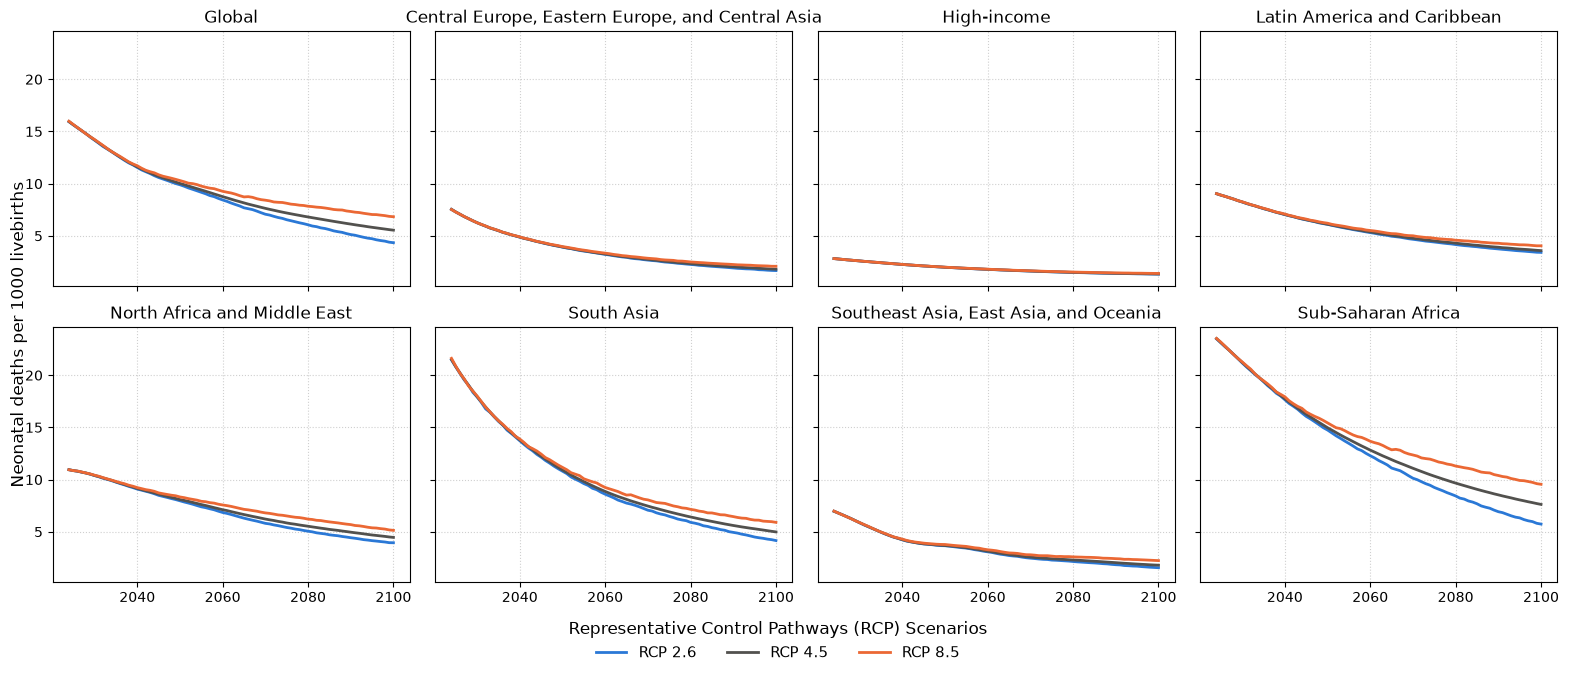

,year_id,location_name,scenario,deaths,pct_change_from_lower_scenario
0,2050,Global,ssp126,40822995,NaN
1,2050,Global,ssp245,41018474,NaN
2,2050,Global,ssp585,41270735,NaN
3,2050,Global,ssp585 - ssp126,447740,1.10
4,2050,Global,ssp585 - ssp245,252262,0.61
...,...,...,...,...,...
91,2100,Sub-Saharan Africa,ssp245,46016014,NaN
92,2100,Sub-Saharan Africa,ssp585,49363706,NaN
93,2100,Sub-Saharan Africa,ssp585 - ssp126,5961879,13.74
94,2100,Sub-Saharan Africa,ssp585 - ssp245,3347692,7.28


In [13]:
# Cumulative scenario difference table and super-region line plots ##########
#
# Reproduced here rather than driven through the pipeline, for one practical
# reason: residual_diagnostics lives only in the rra-climate-health_2 clone,
# while this kernel's rra_climate_health is the other one and has no
# `residual` module at all. Running the pipeline versions would also mean
# writing a fake results version into the shared results tree just so
# `load_shifted_prevalence` had something to read. The arithmetic is the same:
#
#   counts      FHS rate per 1000 / 1000 x live births, at each aggregate
#               level directly. FHS already publishes the aggregate rates,
#               and births are summed to the same level, so nothing about the
#               rate is re-aggregated. Live births and not population, because
#               a probability per birth times a population STOCK is not a
#               count of deaths: the 0-27 day population is about 1/13 of a
#               year's births, so the pipeline's convention reports neonatal
#               deaths ~13x too low.
#   cumulative  cumsum over year from FIRST_FORECAST_YEAR (2024)
#   table       cumulative[A] - cumulative[B] at 2050 and 2100, for the three
#               scenario pairs, at every location of level < 2 (globe and the
#               seven super regions), in whole deaths, with each difference
#               also given as a percent of the lower-emission scenario
nmr_fhs_counts = build_nmr_fhs_counts()
nmr_fhs_table1 = cumulative_difference_table(nmr_fhs_counts)

fig = plot_superregion_rates(nmr_fhs_counts)
fig.savefig(os.path.join(PLOT_OUTPUT, NEONATAL_PLOT_FILE), dpi=200, bbox_inches="tight")
nmr_fhs_table1.to_csv(
    os.path.join(PLOT_OUTPUT, NEONATAL_TABLE_FILE), index=False, encoding="utf-8-sig"
)
plt.show()
nmr_fhs_table1

## Child mortality

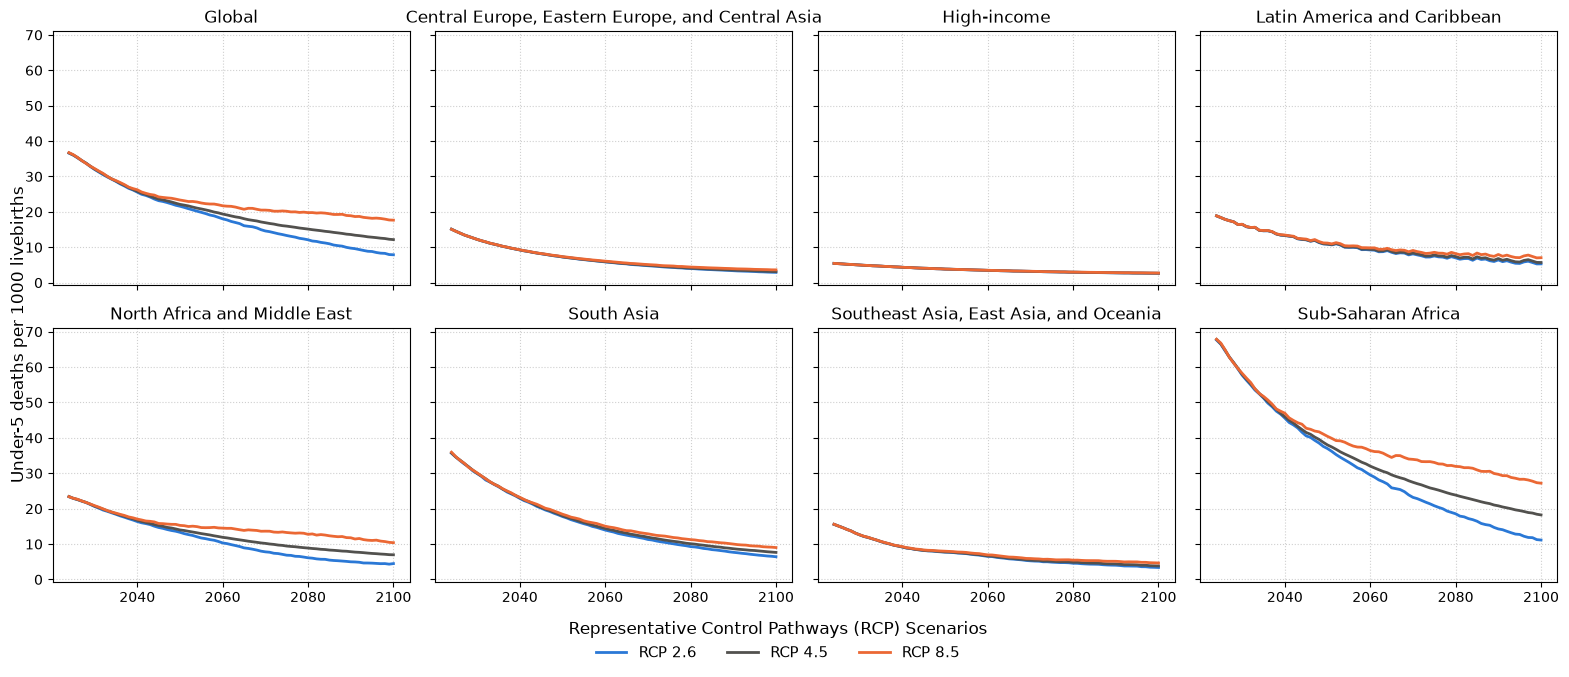

,year_id,location_name,scenario,deaths,pct_change_from_lower_scenario
0,2050,Global,ssp126,91446360,NaN
1,2050,Global,ssp245,92202402,NaN
2,2050,Global,ssp585,93284574,NaN
3,2050,Global,ssp585 - ssp126,1838214,2.01
4,2050,Global,ssp585 - ssp245,1082172,1.17
...,...,...,...,...,...
91,2100,Sub-Saharan Africa,ssp245,118045603,NaN
92,2100,Sub-Saharan Africa,ssp585,134616552,NaN
93,2100,Sub-Saharan Africa,ssp585 - ssp126,27635584,25.83
94,2100,Sub-Saharan Africa,ssp585 - ssp245,16570949,14.04


In [14]:
# Child mortality: cumulative scenario differences and line plots ###########
#
# RRA has no directly usable 5q0, so it is rebuilt from the two parts the
# pipeline does model, draw by draw:
#
#     5q0 = 1 - (1 - 28q0) * (1 - 5q28)
#
#   28q0  neonatal_mortality/results/2026_10_08.01  (original model draws)
#   5q28  child_mortality/results/2026_10_16.01     (original model draws)
#
# Draw by draw and not on the draw means, because the identity is not linear.
# The direct 5q0 run (2026_10_01.01) is properly anchored to GBD but falls
# below 28q0 in 216 locations after 2023, which cannot happen - neonatal
# deaths are a subset of under-5 deaths. The recombination has zero such
# cells, which is why 5q28 was fit separately in the first place.
#
# From there it is the neonatal recipe: take the scenario minus reference
# difference, roll it up the hierarchy weighted by LIVE BIRTHS, and add it to
# the FHS under-5 series exactly as published. Live births and not the
# under-5 population the pipeline uses: 5q0 is a probability per birth, and
# the under-5 population is roughly five years of births stacked up, which is
# why the pipeline's convention reports under-5 deaths ~5x too high.
u5m_fhs_counts = build_u5m_fhs_counts()
u5m_fhs_table1 = cumulative_difference_table(u5m_fhs_counts)

fig = plot_superregion_rates(u5m_fhs_counts, ylabel=U5M_YLABEL)
fig.savefig(os.path.join(PLOT_OUTPUT, U5M_PLOT_FILE), dpi=200, bbox_inches="tight")
u5m_fhs_table1.to_csv(
    os.path.join(PLOT_OUTPUT, U5M_TABLE_FILE), index=False, encoding="utf-8-sig"
)
plt.show()
u5m_fhs_table1